# La energía específica por tamaño de Morrell frente a Bond en los diez muestreos: la ecuación del chancador paso a paso, dos variantes ajustadas con retención y un índice de trabajo negativo leído con honestidad

**Pregunta:** ¿Explica la energía específica por tamaño de Morrell para un chancador convencional, puesta junto a la ley de Bond con las mismas entradas, la potencia del motor eléctrico de los diez muestreos del HP500 cuando se retiene cada muestreo, y qué dice de la mena su término de vacío ajustado?

- **Nivel:** 3, comparación con métodos publicados
- **Requisitos previos:** el notebook 02 de este tema y el notebook 02 del tema 05
- **Tiempo de lectura:** unos 50 minutos

## Objetivos

Al terminar este notebook usted puede:

- escribir la ecuación de Morrell para la energía específica de un chancador convencional, decir qué es cada término y dónde salen sus unidades, y evaluarla sobre un muestreo junto a la energía de Bond para la misma reducción;
- convertir ambas leyes en una columna de diseño, la potencia por unidad de índice de trabajo, y leer qué hace cada columna frente a la potencia medida de los diez muestreos;
- retener cada muestreo por turno y comparar Bond, Morrell y la recta de la abertura con los mismos pliegues y el mismo error;
- reconocer un índice de trabajo ajustado con signo equivocado, decir por qué una variante que predice bien con él no es el modelo de Morrell, y nombrar lo que los muestreos no pueden decidir.

## Preparación

Numpy y matplotlib. Todo lo demás, las ecuaciones de ambas leyes y los ajustes, viene del pipeline del repositorio.

```bash
pip install numpy==2.4.6 matplotlib==3.11.2
```

Las importaciones traen el lector de muestreos, el constructor del modelo base, los módulos del HP500 (la recta de la abertura, el ajuste de Morrell y las funciones de CrusherCal), las ecuaciones de Morrell y el oráculo de Bond.

In [1]:

# Imprima las versiones de las herramientas de este notebook, para compararlas con
# notebooks/requirements.txt
import importlib.metadata as md
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

for name in ('numpy', 'matplotlib'):
    print(name, md.version(name))

# El notebook está tres carpetas bajo la raíz del repositorio; el pipeline se importa por su ruta
ROOT = Path("../../..").resolve()
sys.path.insert(0, str(ROOT / "data-pipeline"))
# Solo funciones públicas del pipeline: el notebook no define ningún método propio
from pipeline.hp500.surveys import read_surveys
from pipeline.hp500 import backbone, blin, loo, morrell_fit
from pipeline.model.crusher import morrell
from pipeline.oracles import bond_energy_kwh_t, bond_power_kw
plt.rcParams.update({"figure.figsize": (7.4, 3.9), "axes.grid": True, "grid.alpha": 0.3, "font.size": 9})


numpy 2.4.6
matplotlib 3.11.2


## Datos

Los diez muestreos del HP500. Propietarios: Rocha, Campos, Silva y Tavares (2024), Minerals 14(9), 919, https://doi.org/10.3390/min14090919. Clase de licencia: CC BY 4.0 (acceso abierto, atribución), véase `conventions/third-party-datasets.md`; las diez filas están transcritas de la Tabla A1 del artículo. Archivos leídos: `data/examples/hp500-surveys.csv` y `VERSION`. Las ecuaciones de Morrell vienen de la guía GMSG sobre el método de Morrell, Anexo B, sección B.2.2 (https://www.smctesting.com/documents/Morrell_method_for_determining_comminution_circuit_specific_energy_and_assessing_energy_utilization_efficiency_of_existing_circuits.pdf), que es la fuente que cita el módulo del pipeline; el artículo primario es Morrell (2009), https://doi.org/10.1016/j.mineng.2009.01.005.

La celda lee la tabla de muestreos y construye el modelo base, cuyo P80 de cada muestreo es el tamaño de producto que ambas leyes necesitan, porque la planta no midió ninguno.

In [2]:

# Los diez muestreos y el P80 del modelo base de cada uno (salida de modelo: entrada abajo, nunca
# objetivo)
surveys = read_surveys().accepted
version = (ROOT / "VERSION").read_text(encoding="utf-8").strip()
bdoc = backbone.build(surveys, version)
rows = bdoc["surveys"]
css = np.array([r["measured"]["css_mm"] for r in rows])
f80 = np.array([r["measured"]["f80_mm"] for r in rows])
tph = np.array([r["measured"]["feed_tph"] for r in rows])
kw = np.array([r["measured"]["power_kw"] for r in rows])
p80 = np.array([r["backbone"]["p80_mm"] for r in rows])
print('muestreos: {} | etiqueta de versión: {}'.format(len(surveys), version))
text = (
    'potencia medida: {:.0f} a {:.0f} kW | alimentación: {:.0f} a '
    '{:.0f} t/h | P80 del modelo base: {:.1f} a {:.1f} mm'
)
print(text.format(kw.min(), kw.max(), tph.min(), tph.max(), p80.min(), p80.max()))


muestreos: 10 | etiqueta de versión: 0.13.000
potencia medida: 187 a 355 kW | alimentación: 813 a 1639 t/h | P80 del modelo base: 21.2 a 36.6 mm


## Método

**Paso 1, la ecuación de Morrell para un muestreo.** El método de Morrell valora una reducción de tamaño en un chancador, en la forma de la guía GMSG (Anexo B, sección B.2.2, ecuaciones B4 y B5), como

$$W_c = S_c\,K_2\,M_{ic}\;4\left(x_2^{f(x_2)} - x_1^{f(x_1)}\right)\ [\mathrm{kWh/t}],\qquad f(x) = -\left(0{,}295 + \frac{x}{10^{6}}\right),\qquad S_c = \min\left(1,\ 55\,(x_1 x_2)^{-0{,}2}\right)$$

con $x_1$ y $x_2$ los tamaños de 80 por ciento pasante de la alimentación y del producto en micrómetros, $K_2$ igual a 1,0 para un chancador en circuito cerrado con una zaranda clasificadora (y 1,19 en circuito abierto; las funciones del pipeline toman el circuito cerrado por omisión y este notebook lo mantiene, lo que no cambia ningún resultado de abajo porque el índice ajustado absorbe cualquier factor constante), y $M_{ic}$ el índice de trabajo del chancador de la mena en kWh/t, medido con el ensayo SMC. La ley de Bond ($W = 10\,W_i\,(P_{80}^{-1/2} - F_{80}^{-1/2})$) da el mismo tipo de respuesta, una energía por tonelada, con otra dependencia del tamaño. El término de tamaño no tiene dimensión, un tamaño en micrómetros elevado a una potencia negativa pequeña, así que $W_c$ lleva la unidad de $M_{ic}$, y $W_c$ por el caudal en t/h es una potencia en kW. La celda evalúa cada término sobre el muestreo 1 con $M_{ic} = 1$ kWh/t, tomando $x_1$ del f80 medido y $x_2$ del P80 del modelo base, e imprime la energía de Bond para la misma reducción con $W_i = 1$ kWh/t para poder leer las dos leyes por unidad de su índice.

In [3]:

# La ecuación B4 de la guía sobre el muestreo 1, un término a la vez, con M_ic = 1 kWh/t
x1, x2 = f80[0] * 1000, p80[0] * 1000
size = morrell.size_term(x1, x2)
s_c = morrell.hardness_parameter(x1, x2)
w_c = morrell.crusher_specific_energy_kwh_t(x1, x2, 1.0)
w_bond = bond_energy_kwh_t(f80[0], p80[0], 1.0)
print((
    'f(x1) = {:.4f}, f(x2) = {:.4f} con x1 = {:.0f} um y x2 = '
    '{:.0f} um'
).format(morrell.f_exponent(x1), morrell.f_exponent(x2), x1, x2))
print('término de tamaño 4 (x2^f(x2) - x1^f(x1)) = {:.5f}'.format(size))
print('parámetro de dureza S_c = {:.4f}'.format(s_c))
print('W_c = S_c K2 M_ic término de tamaño = {:.5f} kWh/t (M_ic = 1)'.format(w_c))
print((
    'energía de Bond de la misma reducción con Wi = 1 kWh/t = '
    '{:.5f} kWh/t'
).format(w_bond))


f(x1) = -0.3830, f(x2) = -0.3276 con x1 = 88000 um y x2 = 32560 um
término de tamaño 4 (x2^f(x2) - x1^f(x1)) = 0.08192
parámetro de dureza S_c = 0.7062
W_c = S_c K2 M_ic término de tamaño = 0.05785 kWh/t (M_ic = 1)
energía de Bond de la misma reducción con Wi = 1 kWh/t = 0.02171 kWh/t


En el muestreo 1 la alimentación tiene un f80 de 88 mm y el producto del modelo base un P80 de 32,56 mm, una razón de reducción de 2,7. El término de tamaño vale 0,08192, el parámetro de dureza $S_c$ vale 0,7062 (menor que 1, así que la corrección de la guía actúa y la energía baja casi un tercio), y la energía por unidad de índice de trabajo es 0,05785 kWh/t, frente a 0,02171 kWh/t de Bond con el mismo $W_i$ de 1. La ley de Morrell valora entonces esta reducción en 2,7 veces la de Bond para un índice unitario, lo que no es un desacuerdo: los dos índices son ensayos distintos en escalas distintas, y cada mena trae su propio valor de cada uno. Lo que importa abajo es qué hace cada ley con el tamaño y el caudal una vez ajustado su índice. La celda siguiente pregunta si el límite en 1 de la guía importa alguna vez en estos muestreos.

In [4]:

# El parámetro de dureza de cada muestreo, para ver si el límite en 1 de la guía actúa alguna vez
s_all = [morrell.hardness_parameter(a * 1000, b * 1000) for a, b in zip(f80, p80)]
print('S_c en los diez muestreos: {:.3f} a {:.3f}'.format(min(s_all), max(s_all)))


S_c en los diez muestreos: 0.629 a 0.872


$S_c$ va de 0,629 a 0,872 en los diez muestreos: la corrección actúa en todos y el límite nunca, así que la regla `min(1, ...)` de la guía no es lo que separa un muestreo de otro. $S_c$ baja al crecer los tamaños, de modo que recorta más la energía en las reducciones más gruesas.

**Paso 2, la columna de diseño.** El pipeline escribe ambas leyes como una potencia lineal en una incógnita. Para un muestreo con f80 medido, P80 del modelo base y caudal de alimentación medido $Q$, la potencia que predice Morrell es $M_{ic}\,g$ con $g = W_c(M_{ic} = 1)\,Q$ en kW por kWh/t (`morrell_fit.design_column`), y la que predice Bond es $W_i\,g_B$ con $g_B = W(W_i = 1)\,Q$. Poner el caudal medido en la columna es una decisión del modelo, porque el caudal de la planta es una entrada de la pregunta de potencia; el P80 es el del modelo base y también es una entrada, nunca un objetivo, porque la planta no midió ninguno. La celda construye ambas columnas para los diez muestreos y las imprime con la abertura y la potencia medida.

In [5]:

# La columna de diseño de cada muestreo: kW por kWh/t de índice, para Morrell y para Bond, con el t/h
# medido
g_morrell = morrell_fit.design_column(f80, p80, tph)
g_bond = np.array([bond_power_kw(q, a, b, 1.0) for q, a, b in zip(tph, f80, p80)])
print((
    'muestreo  CSS [mm]  f80 [mm]  P80 [mm]    t/h  kW medido  g '
    'Morrell  g Bond'
))
for k in range(len(kw)):
    print(f"{k + 1:6d} {css[k]:9.0f} {f80[k]:9.0f} {p80[k]:9.2f} {tph[k]:6.0f}", end=" ")
    print(f"{kw[k]:11.0f} {g_morrell[k]:10.1f} {g_bond[k]:7.1f}")


muestreo  CSS [mm]  f80 [mm]  P80 [mm]    t/h  kW medido  g Morrell  g Bond
     1        54        88     32.56   1639         209       94.8    35.6
     2        54        84     31.36   1267         212       74.5    27.8
     3        48        47     21.23   1240         262       76.0    27.9
     4        48        88     30.80   1034         349       64.1    24.1
     5        48        62     24.54   1124         325       72.4    26.6
     6        40        79     26.54    813         355       56.4    21.0
     7        38       140     36.60   1050         306       65.7    26.8
     8        44       123     35.69   1138         325       70.2    27.8
     9        40        81     26.97    820         350       56.7    21.1
    10        55        81     30.72   1334         187       78.6    29.2


La columna de Morrell va de 56,4 a 94,8 kW por kWh/t y la de Bond de 21,0 a 35,6; la razón entre ambas está entre 2,45 y 2,73, así que en estos muestreos las dos leyes son casi proporcionales, a menos de un 10 por ciento de un factor de escala: lo que una hace con los datos, la otra lo hace con ese factor y una leve inclinación. La potencia medida abarca de 187 a 355 kW. Cada unidad de índice de trabajo compra más potencia en el muestreo de gran caudal, así que la pregunta para ambas leyes es si las columnas ordenan los muestreos como lo hace el motor eléctrico. La celda lo cuenta con la correlación, y agrega la abertura como referencia.

In [6]:

# Correlación de cada columna de diseño, y de la abertura, con la potencia medida
r_morrell = np.corrcoef(g_morrell, kw)[0, 1]
r_bond = np.corrcoef(g_bond, kw)[0, 1]
r_css = np.corrcoef(css, kw)[0, 1]
print((
    'correlación con los kW medidos: columna de Morrell {:.2f}, '
    'columna de Bond {:.2f}, abertura CSS {:.2f}'
).format(r_morrell, r_bond, r_css))


correlación con los kW medidos: columna de Morrell -0.81, columna de Bond -0.78, abertura CSS -0.82


La figura traza la potencia medida contra cada columna, un punto por muestreo, numerado como en la tabla.

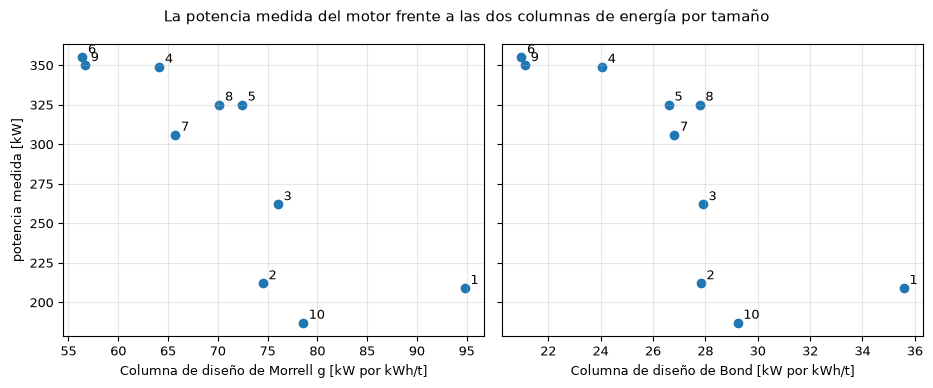

In [7]:

# Potencia medida frente a cada columna de diseño, un punto por muestreo
fig, axes = plt.subplots(1, 2, figsize=(9.4, 3.9), sharey=True)
panels = (
    (g_morrell, 'Columna de diseño de Morrell g [kW por kWh/t]'),
    (g_bond, 'Columna de diseño de Bond [kW por kWh/t]'),
)
for ax, (column, xlabel) in zip(axes, panels):
    ax.scatter(column, kw, color="tab:blue")
    for k in range(len(kw)):
        ax.annotate(str(k + 1), (column[k], kw[k]), textcoords="offset points", xytext=(4, 3))
    ax.set_xlabel(xlabel)
axes[0].set_ylabel('potencia medida [kW]')
fig.suptitle((
    'La potencia medida del motor frente a las dos columnas de '
    'energía por tamaño'
))
fig.tight_layout()
plt.show()


Ambas columnas se correlacionan negativamente con la potencia medida (-0,81 para Morrell, -0,78 para Bond), casi tan fuerte como la propia abertura (-0,82). De ello se siguen dos cosas. Una ley cuya predicción es proporcional a su columna, que es todo modelo con índice de trabajo y sin intercepto, predice la mayor potencia donde la columna es mayor, y la figura muestra que ahí es donde el motor eléctrico consume menos: los muestreos de gran caudal y abertura gruesa. Y el signo no es un accidente de las constantes de Morrell, pues la columna de Bond hace lo mismo; viene de lo que hizo la planta: los muestreos con la abertura más fina tienen el menor caudal y la mayor potencia medida. La figura no muestra que la ecuación de Morrell sea errónea para chancadores en general; muestra que con estos datos el producto de una energía por tonelada y el caudal medido apunta en sentido contrario: el motor eléctrico consumió menos potencia donde el caudal de alimentación fue mayor.

## Comparación

El índice de Morrell no está publicado para la itabirita de Minas Rio, así que hay que ajustarlo, y el de Bond también (el motor de cálculo trae un valor de mezcla, $W_i$ = 9 kWh/t, de las bandas del artículo). La comparación usa el protocolo del propio producto, dejando un muestreo fuera de forma estricta: cada modelo se reajusta con nueve muestreos, con `morrell_fit.fit_through_origin` para el índice solo y `morrell_fit.fit_with_no_load` para el índice más una potencia de vacío (la guía define la potencia neta como la potencia del motor eléctrico menos el vacío, así que una potencia medida en el motor lo lleva), y predice el décimo. Siete modelos corren sobre los mismos pliegues. El primero es la potencia propia del producto en esta máquina, la forma basada en la corriente $P_c = 1{,}30\,P_d + 110$ kW de Rocha et al. (2024), con $P_d$ el consumo de Bond con la capacidad, el F80 y el P80 propios del motor y el índice de mezcla de 9 kWh/t: el documento de la columna vertebral construido arriba la guarda por muestreo como `calibrated_power_kw`, y como nada en ella se reajusta en los pliegues es la misma en cada pliegue. Luego Bond con el índice de mezcla sobre la capacidad medida sin ajuste, que no usa pendiente ni término de vacío y por eso no es la potencia del motor de cálculo, Bond reajustado, Bond con término de vacío, Morrell reajustado, Morrell con término de vacío, y, como vara de medir, la recta de la abertura, una recta de la potencia sobre la abertura de descarga reajustada con los nueve muestreos de cada pliegue (`blin.fit_line`). El error es el error porcentual absoluto medio de la potencia con retención.

Escrito completo, el protocolo para una ley con columna de diseño $g$ (la de Morrell o la de Bond) y el muestreo $i$ retenido es

$$\bigl(\hat M_{-i}, \hat P_{0,-i}\bigr) = \arg\min_{M,\,P_0} \sum_{j \ne i} \bigl(P_j - M g_j - P_0\bigr)^2, \qquad \hat P_{-i} = \hat M_{-i}\, g_i + \hat P_{0,-i}, \qquad \mathrm{MAPE} = \frac{100}{n} \sum_{i=1}^{n} \frac{|P_i - \hat P_{-i}|}{P_i},$$

donde $P_j$ es la potencia medida del motor en el muestreo $j$ en kW, $g_j$ su columna de diseño en kW por kWh/t, $M$ el índice de trabajo de la ley ($M_{ic}$ o $W_i$), $P_0$ la potencia en vacío (fija en cero para las variantes por el origen), $\hat P_{-i}$ la predicción del muestreo retenido desde los otros nueve, y $n = 10$. El muestreo retenido nunca entra a su propio ajuste, que es lo que hace del error una estimación de cómo le iría a la ley en un undécimo muestreo.

In [8]:

# Dejando un muestreo fuera: cada modelo se reajusta con nueve muestreos y predice el décimo
names = ("engine_power", "bond_nominal", "bond", "bond_noload", "morrell", "morrell_noload", "b_lin")
n = len(kw)
held = {name: np.zeros(n) for name in names}
fitted = []
for i in range(n):
    train = np.array([j for j in range(n) if j != i])
    held["engine_power"][i] = rows[i]["backbone"]["calibrated_power_kw"]   # Pc = 1,30 Pd + 110, sin ajuste
    held["bond_nominal"][i] = 9.0 * g_bond[i]
    held["bond"][i] = morrell_fit.fit_through_origin(g_bond, kw, train) * g_bond[i]
    m_b, p_b = morrell_fit.fit_with_no_load(g_bond, kw, train)
    held["bond_noload"][i] = m_b * g_bond[i] + p_b
    held["morrell"][i] = morrell_fit.fit_through_origin(g_morrell, kw, train) * g_morrell[i]
    m_m, p_m = morrell_fit.fit_with_no_load(g_morrell, kw, train)
    held["morrell_noload"][i] = m_m * g_morrell[i] + p_m
    fitted.append((m_m, p_m))
    held["b_lin"][i] = blin.predict_line(blin.fit_line(css, kw, train), css[i])


La celda siguiente imprime el error con retención de los siete modelos, el error porcentual absoluto medio y la raíz del error cuadrático medio en kW, para leer el orden en un solo lugar.

In [9]:

# Error con retención de cada modelo sobre la potencia
label = {
    "engine_power": 'potencia HP500 del motor, 1,30 Pd + 110',
    "bond_nominal": 'Bond, Wi = 9 sobre la Q medida, sin ajuste',
    "bond": 'Bond, Wi reajustado por el origen',
    "bond_noload": 'Bond, Wi y un término de vacío',
    "morrell": 'Morrell, M_ic reajustado por el origen',
    "morrell_noload": 'Morrell, M_ic y un término de vacío',
    "b_lin": 'la recta de la abertura',
}
print('modelo                                    MAPE [%]  RMSE [kW]')
for name in names:
    print(f"{label[name]:42s} {loo.mape(kw, held[name]):8.2f} {loo.rmse(kw, held[name]):10.2f}")
print("potencia HP500 del motor: {:.1f} a {:.1f} kW, correlación con la potencia medida {:+.2f}".format(
    held["engine_power"].min(), held["engine_power"].max(), np.corrcoef(kw, held["engine_power"])[0, 1]))
print(f"la potencia medida: {kw.min():.0f} a {kw.max():.0f} kW")


modelo                                    MAPE [%]  RMSE [kW]
potencia HP500 del motor, 1,30 Pd + 110       47.58     132.85
Bond, Wi = 9 sobre la Q medida, sin ajuste    31.72     103.73
Bond, Wi reajustado por el origen             36.44     109.72
Bond, Wi y un término de vacío                16.27      47.28
Morrell, M_ic reajustado por el origen        38.08     111.67
Morrell, M_ic y un término de vacío           15.21      46.53
la recta de la abertura                       12.78      44.56
potencia HP500 del motor: 365.0 a 418.7 kW, correlación con la potencia medida -0.45
la potencia medida: 187 a 355 kW


La potencia HP500 propia del producto es la peor fila de la tabla, 47,58 por ciento con un RMSE de 132,85 kW: predice de 365,0 a 418,7 kW para cada muestreo, así que su predicción más baja queda sobre la potencia medida más alta, 355 kW, y se correlaciona -0,45 con la potencia medida, así que además ordena los muestreos al revés. Con retención, Bond con el índice de mezcla sobre la capacidad medida da 31,72 por ciento, Bond reajustado 36,44, Morrell reajustado 38,08, y las dos variantes con término de vacío 16,27 para Bond y 15,21 para Morrell, frente a 12,78 de la recta de la abertura. El Morrell por el origen es el peor de todos, y no mejor que Bond reajustado en la misma forma (36,44): en estos muestreos la energía específica por tamaño publicada no supera a la ley más antigua, solo la reformula. Agregar un término de vacío convierte 38,08 en 15,21, una ganancia grande, y lleva a Morrell a 2,44 puntos de una recta que no usa nada salvo la abertura. Bond con el mismo término extra llega a 16,27, solo 1,05 puntos atrás, así que la ganancia viene del intercepto y no de la ley de tamaño de Morrell. La celda siguiente comprueba que estos números son los del propio pipeline.

In [10]:

# Una comprobación de reproducción: el documento con retención del pipeline, construido en vivo, da el
# mismo MAPE
strict = loo.build(bdoc, version)["loo"]["kW"]["strict"]
ours = (loo.mape(kw, held["morrell"]), loo.mape(kw, held["morrell_noload"]), loo.mape(kw, held["b_lin"]))
theirs = (strict["Morrell"]["mape_pct"], strict["Morrell_noload"]["mape_pct"], strict["B_lin"]["mape_pct"])
for tag, a, b in zip(("Morrell reajustado", "Morrell con término de vacío", "la recta de la abertura"), ours, theirs):
    print('{:32s} aquí {:6.2f} %, pipeline {:6.2f} %'.format(tag, a, b))
print('los tres coinciden: {}'.format(np.allclose(ours, theirs, atol=0.005)))


Morrell reajustado               aquí  38.08 %, pipeline  38.08 %
Morrell con término de vacío     aquí  15.21 %, pipeline  15.21 %
la recta de la abertura          aquí  12.78 %, pipeline  12.78 %
los tres coinciden: True


Los tres valores coinciden hasta el segundo decimal, así que el bucle de pliegues de este notebook es el del documento de validación del producto; los otros cuatro modelos (la potencia propia del motor, Bond con el índice de mezcla, Bond reajustado y Bond con término de vacío) no tienen contraparte en ese documento y son lo que este notebook agrega. La figura traza la potencia medida contra la predicción con retención de cinco modelos: la potencia propia del motor, Bond reajustado, Morrell y Morrell con término de vacío, y la recta de la abertura, con la recta de identidad.

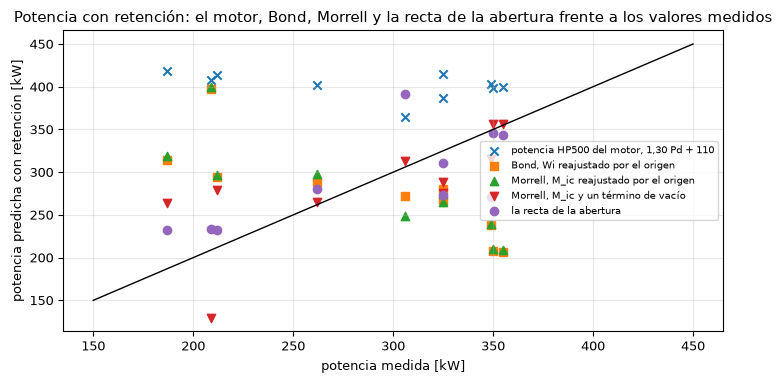

In [11]:

# Potencia medida frente a la predicción con retención de cinco modelos
fig, ax = plt.subplots()
for name, marker in (("engine_power", "x"), ("bond", "s"), ("morrell", "^"), ("morrell_noload", "v"), ("b_lin", "o")):
    ax.scatter(kw, held[name], marker=marker, label=label[name])
ax.plot([150, 450], [150, 450], color="black", lw=1)
ax.set_xlabel('potencia medida [kW]')
ax.set_ylabel('potencia predicha con retención [kW]')
ax.set_title((
    'Potencia con retención: el motor, Bond, Morrell y la recta de la abertura frente '
    'a los valores medidos'
))
ax.legend(fontsize=7)
fig.tight_layout()
plt.show()


Los puntos sobre la recta de identidad son predicciones perfectas. La potencia propia del motor de cálculo, las cruces, es una banda plana entre 365 y 419 kW sin importar lo que consumió la planta: su término de vacío de 110 kW y su pendiente de 1,30 levantan un consumo de Bond que apenas cambia entre muestreos por sobre todas las mediciones. Los modelos por el origen, Bond reajustado y Morrell, forman una nube que baja a medida que sube la potencia medida, muy por encima de la recta en las potencias medidas bajas y por debajo en las altas, la forma de un modelo cuya pendiente tiene el signo equivocado forzado por el origen; su RMSE con retención es 109,7 y 111,7 kW sobre un rango medido de 187 a 355 kW. Morrell con término de vacío y la recta de la abertura quedan más cerca de la recta, con una dispersión de 46,5 y 44,6 kW. La figura no dice por qué funciona la variante con vacío; la banda de abajo y luego los coeficientes sí.

La dispersión se puede resumir en un número como lo hace CrusherCal para su propio modelo: la banda predictiva de 80 por ciento de un modelo con retención es su predicción más o menos 1,2816 veces la desviación estándar de sus residuos con retención (`loo.predictive_band`). La celda imprime esa banda para los cuatro modelos que muestra la figura.

In [12]:

# La banda predictiva de 80 por ciento de cada modelo con retención, con la función de CrusherCal
print((
    'modelo                                    sigma [kW]  '
    'semiancho [kW]'
))
for name in ("bond", "morrell", "morrell_noload", "b_lin"):
    band = loo.predictive_band(kw - held[name])
    print(f"{label[name]:42s} {band['sigma']:9.1f} {band['halfwidth']:20.1f}")


modelo                                    sigma [kW]  semiancho [kW]
Bond, Wi reajustado por el origen              115.0                147.4
Morrell, M_ic reajustado por el origen         117.0                150.0
Morrell, M_ic y un término de vacío             48.9                 62.7
la recta de la abertura                         46.8                 60.0


La banda de 80 por ciento de Bond reajustado es más o menos 147 kW y la de Morrell más o menos 150 kW, más ancha que todo el rango medido de 168 kW (de 187 a 355): una banda tan ancha no dice nada de qué muestreo consume más. Morrell con término de vacío da más o menos 63 kW y la recta de la abertura más o menos 60 kW, cerca de un tercio de ese rango a cada lado. La banda es el costo de la predicción en kW, y reproduce el orden del MAPE: las leyes por el origen no llevan información sobre la potencia de un muestreo retenido, y la recta con vacío la lleva solo porque su columna contiene el caudal medido, como muestran las celdas de abajo.

**El índice de trabajo negativo.** Un índice de trabajo es una propiedad medida de una roca, una energía positiva. La variante con término de vacío ajusta dos números por pliegue, y la celda los imprime: el índice $M_{ic}$ que eligió el pliegue, la potencia de vacío, y si el índice es positivo. El pipeline marca lo mismo en su documento como `noload_variant_m_ic_positive`.

In [13]:

# Los coeficientes que cada pliegue ajustó para Morrell con un término de vacío
print('muestreo retenido   M_ic [kWh/t]   vacío [kW]   M_ic positivo')
for k, (m_ic, no_load) in enumerate(fitted):
    print(f"{k + 1:16d} {m_ic:14.2f} {no_load:14.1f} {m_ic > 0!s:>14}")
print('menor potencia medida en los diez muestreos: {:.0f} kW'.format(kw.min()))


muestreo retenido   M_ic [kWh/t]   vacío [kW]   M_ic positivo
               1          -6.29          726.7          False
               2          -4.46          611.0          False
               3          -4.65          618.4          False
               4          -4.46          601.4          False
               5          -4.73          618.5          False
               6          -4.68          620.2          False
               7          -4.70          622.0          False
               8          -4.64          613.5          False
               9          -4.74          625.2          False
              10          -4.16          590.7          False
menor potencia medida en los diez muestreos: 187 kW


El índice es negativo en los diez pliegues, de -6,3 a -4,2 kWh/t, y la potencia de vacío ajustada va de 591 a 727 kW, de 3,2 a 3,9 veces la menor potencia que el motor eléctrico consumió, 187 kW, en un chancador cuyo consumo en vacío no puede superar lo que consume cargado. Ninguno de los dos números es físico. Un $M_{ic}$ negativo significa que la energía que la ley asigna al muestreo se resta: el ajuste encontró que la potencia baja cuando sube la columna de Morrell (la correlación de la figura anterior) y resolvió una pendiente negativa y un intercepto lo bastante grande para devolver la recta a los datos. La predicción es entonces una recta de pendiente negativa en una columna que sube tanto con el caudal como con la abertura, de modo que puede ser un buen predictor sin que la ecuación se use como ley de energía. La celda mide a qué siguen la columna y la predicción, y puntúa la recta de la abertura con retención, ajustada con el caudal en lugar de la abertura.

In [14]:

# A qué sigue la variante con vacío: la columna de diseño y la predicción con retención frente al caudal,
# la abertura y la recta de la abertura
pairs = (
    ('correlación de la columna g de Morrell con el caudal', g_morrell, tph),
    ('correlación de la columna g de Morrell con la abertura CSS', g_morrell, css),
    ('correlación del caudal con la abertura CSS', tph, css),
    ('correlación del caudal con los kW medidos', tph, kw),
    ('correlación de la predicción con vacío con el caudal', held["morrell_noload"], tph),
    ('correlación de la predicción con vacío con la abertura CSS', held["morrell_noload"], css),
    ('correlación, predicción con vacío y recta de la abertura', held["morrell_noload"], held["b_lin"]),
)
for tag, first, second in pairs:
    print(f"{tag:62s} {np.corrcoef(first, second)[0, 1]:+.2f}")
# La propia recta con retención de la recta de la abertura, ajustada sobre el caudal en lugar de la abertura
held_tph = np.zeros(n)
for i in range(n):
    train = np.delete(np.arange(n), i)
    held_tph[i] = blin.predict_line(blin.fit_line(tph, kw, train), tph[i])
print(f"recta con retención de la potencia sobre el caudal: MAPE {loo.mape(kw, held_tph):.2f} %, "
      f"RMSE {loo.rmse(kw, held_tph):.2f} kW")


correlación de la columna g de Morrell con el caudal           +0.99
correlación de la columna g de Morrell con la abertura CSS     +0.79
correlación del caudal con la abertura CSS                     +0.81
correlación del caudal con los kW medidos                      -0.85
correlación de la predicción con vacío con el caudal           -0.96
correlación de la predicción con vacío con la abertura CSS     -0.71
correlación, predicción con vacío y recta de la abertura       +0.66
recta con retención de la potencia sobre el caudal: MAPE 14.37 %, RMSE 42.41 kW


La columna de diseño es el caudal con otro nombre: se correlaciona +0,99 con las t/h medidas y +0,79 con la abertura, y en estos diez muestreos el caudal y la abertura se mueven juntos (+0,81). Los valores con retención de la variante con vacío siguen al caudal (-0,96) más de cerca que a la abertura (-0,71) o a la recta de la abertura (+0,66). Una recta simple con retención de la potencia sobre el caudal, el ajuste por mínimos cuadrados de la recta de la abertura con la columna de t/h en lugar de la abertura, logra 14,37 por ciento y 42,41 kW, mejor que Morrell con término de vacío (15,21 por ciento y 46,53 kW): la variante es una recta sobre el caudal de alimentación medido, y la ley de energía de Morrell solo agrega la pequeña inclinación entre su columna y el caudal, que le cuesta precisión. A cuál de los dos sigue el motor eléctrico, estos muestreos no lo pueden decir: el caudal se correlaciona -0,85 con la potencia medida y la abertura -0,82, y los dos están ligados entre sí. Es una recta descriptiva y el producto la informa como tal. La figura traza las dos rectas ajustadas con los diez muestreos en el plano de la columna, para ver qué hace el ajuste.

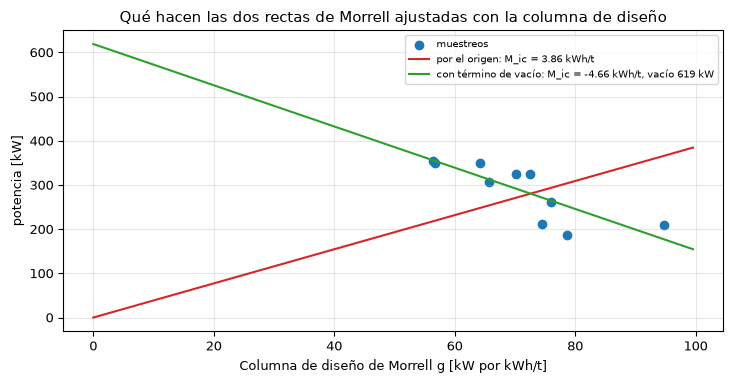

In [15]:

# Las dos rectas de Morrell ajustadas con los diez muestreos, en el plano de la columna de diseño
every = np.arange(n)
m_all = morrell_fit.fit_through_origin(g_morrell, kw, every)
m_nl, p_nl = morrell_fit.fit_with_no_load(g_morrell, kw, every)
x = np.linspace(0, g_morrell.max() * 1.05, 50)
fig, ax = plt.subplots()
ax.scatter(g_morrell, kw, color="tab:blue", label='muestreos')
label_o = 'por el origen: M_ic = {:.2f} kWh/t'.format(m_all)
label_n = 'con término de vacío: M_ic = {:.2f} kWh/t, vacío {:.0f} kW'.format(m_nl, p_nl)
ax.plot(x, m_all * x, color="tab:red", label=label_o)
ax.plot(x, m_nl * x + p_nl, color="tab:green", label=label_n)
ax.set_xlabel('Columna de diseño de Morrell g [kW por kWh/t]')
ax.set_ylabel('potencia [kW]')
ax.set_title((
    'Qué hacen las dos rectas de Morrell ajustadas con la columna '
    'de diseño'
))
ax.legend(fontsize=7)
fig.tight_layout()
plt.show()


Ajustada con los diez muestreos, la recta por el origen tiene un índice de 3,86 kWh/t y sube por el medio de una nube que baja; la recta con término de vacío tiene un índice de -4,66 kWh/t y una potencia de vacío de 619 kW, cae a lo largo de la nube y es la mejor descripción de los puntos. La figura muestra por qué falla el modelo de índice positivo y no el de índice negativo: los datos piden una pendiente descendente y la ecuación, con un índice de trabajo que es una energía positiva, solo puede dar una ascendente. No muestra que otra definición de la alimentación, o el índice de Morrell medido con el ensayo SMC sobre la mena real, no daría un ajuste positivo; los diez muestreos no contienen esa medición.

### Sensibilidad de la comparación: el tamaño de producto prestado y el factor de circuito

Dos entradas de la comparación no son mediciones. El P80 del producto de cada muestreo es el de la columna vertebral, porque la planta no midió ninguno, y el factor de circuito $K_2$ está fijado en el 1,0 de circuito cerrado aunque el circuito del HP500 podría leerse como abierto (1,19). Si alguna de esas elecciones decidiera el veredicto, el veredicto sería sobre la elección. La celda escala todos los P80 de la columna vertebral por un factor común de 0,7 a 1,3, reconstruye las dos columnas de diseño, vuelve a correr el ajuste estricto dejando un muestreo fuera de las cuatro leyes ajustadas y registra el MAPE retenido de cada una; luego repite la comparación con el P80 verdadero y el factor de circuito abierto. La recta de la abertura lee solo la abertura, así que es la referencia plana.

In [16]:
# MAPE retenido de las cuatro leyes ajustadas con cada P80 escalado, y con el factor de circuito abierto K2 = 1.19
def held_out_mape(column, with_no_load):
    pred = np.zeros(n)
    for i in range(n):
        train = np.array([j for j in range(n) if j != i])
        if with_no_load:
            m_i, p_i = morrell_fit.fit_with_no_load(column, kw, train)
            pred[i] = m_i * column[i] + p_i
        else:
            pred[i] = morrell_fit.fit_through_origin(column, kw, train) * column[i]
    return loo.mape(kw, pred)
scales = np.linspace(0.7, 1.3, 7)
curves = {"morrell": [], "morrell_noload": [], "bond": [], "bond_noload": []}
for s in scales:
    gm = morrell_fit.design_column(f80, p80 * s, tph)
    gb = np.array([bond_power_kw(q, a, b * s, 1.0) for q, a, b in zip(tph, f80, p80)])
    variants = (("morrell", gm, False), ("morrell_noload", gm, True), ("bond", gb, False), ("bond_noload", gb, True))
    for key, column, nl in variants:
        curves[key].append(held_out_mape(column, nl))
open_col = morrell_fit.design_column(f80, p80, tph, closed_circuit=False)
print("circuito abierto, Morrell por el origen y con vacío [%]:",
      round(held_out_mape(open_col, False), 2), round(held_out_mape(open_col, True), 2))
for key, values in curves.items():
    print(f"{label[key]:42s} MAPE sobre las escalas de P80: {min(values):6.2f} a {max(values):6.2f} %")

circuito abierto, Morrell por el origen y con vacío [%]: 38.08 15.21
Morrell, M_ic reajustado por el origen     MAPE sobre las escalas de P80:  35.22 a  40.09 %
Morrell, M_ic y un término de vacío        MAPE sobre las escalas de P80:  14.71 a  18.13 %
Bond, Wi reajustado por el origen          MAPE sobre las escalas de P80:  33.34 a  38.81 %
Bond, Wi y un término de vacío             MAPE sobre las escalas de P80:  14.66 a  18.10 %


La figura dibuja las cuatro curvas frente al factor común, con el error retenido de la recta de la abertura como una línea horizontal segmentada, para que cada ley se lea frente a la barra que tiene que superar en cada escala del tamaño de producto prestado.

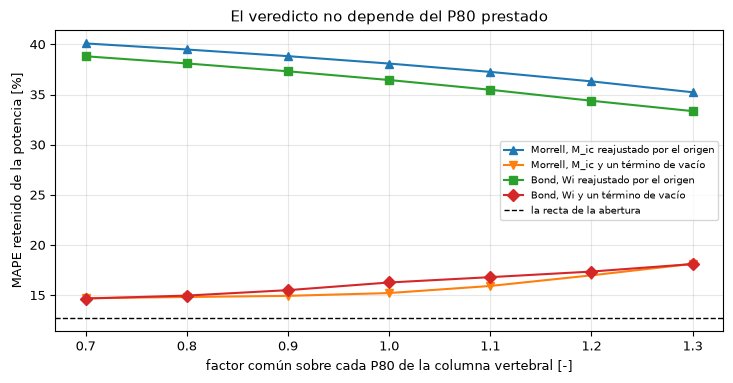

In [17]:
# Dibuje el MAPE retenido de cada ley ajustada frente al factor común de P80, con la recta de la abertura como
# referencia plana
fig, ax = plt.subplots()
for key, marker in (("morrell", "^"), ("morrell_noload", "v"), ("bond", "s"), ("bond_noload", "D")):
    ax.plot(scales, curves[key], marker + "-", label=label[key])
ax.axhline(loo.mape(kw, held["b_lin"]), color="black", lw=1, ls="--", label=label["b_lin"])
ax.set_xlabel("factor común sobre cada P80 de la columna vertebral [-]")
ax.set_ylabel("MAPE retenido de la potencia [%]")
ax.set_title("El veredicto no depende del P80 prestado")
ax.legend(fontsize=7)
fig.tight_layout()
plt.show()

El veredicto sobrevive a las dos entradas prestadas. Con un error de 30 por ciento en cada P80, hacia arriba o hacia abajo, las leyes por el origen quedan muy por detrás de la recta de la abertura y las variantes con vacío quedan cerca de ella sin superarla; los rangos que imprime la celda sobre la figura dan los extremos. Escalar el P80 mueve las curvas porque mueve el término de tamaño de manera desigual entre muestreos, no porque arregle el signo de la columna: la capacidad sigue multiplicando cada columna, y la capacidad sigue yendo en contra de la potencia medida. El circuito abierto deja los dos errores de Morrell exactamente donde estaban con el P80 verdadero, 38,08 y 15,21 por ciento, porque $K_2$ multiplica la columna de cada muestreo por el mismo 1,19 y el índice ajustado lo absorbe. Lo que el barrido no puede variar es el tamaño de producto muestreo por muestreo; un P80 medido en cada muestreo es la única entrada que todavía podría cambiar el cuadro, y el artículo no informa ninguno.

### Úsalo con tus propios datos: la potencia de Morrell para tu propio chancador e índice

Las funciones reciben cualquier registro, así que un lector con un ensayo SMC de su propio mineral puede poner precio a una reducción de chancado con ellas directamente: `crusher_specific_energy_kwh_t` para la energía por tonelada y `crusher_power_kw` para la potencia del motor, ambas con los tamaños en micrómetros, el índice en kWh/t, la capacidad en t/h, una potencia en vacío opcional en kW y el circuito como una marca. Qué mirar en la salida: $S_c$ bajo uno (la corrección de la guía actúa) o limitado en uno, el término de tamaño positivo (un producto más fino que la alimentación), y la potencia junto a la potencia medida del motor en el mismo período, nunca junto a la de un modelo. El registro de abajo está escrito para mostrar la llamada y no es una propiedad de ningún mineral: un cono a 600 t/h de F80 120 mm a P80 28 mm, un índice de 8 kWh/t y una potencia en vacío de 60 kW. La celda imprime la energía y la potencia en los dos circuitos y la potencia de Bond de la misma reducción con el índice de mezcla del motor, 9 kWh/t.

In [18]:
# Energía y potencia de Morrell para un registro escrito (ponga el suyo), en los dos circuitos, junto a Bond
own = {"f80_mm": 120.0, "p80_mm": 28.0, "tph": 600.0, "m_ic": 8.0, "no_load_kw": 60.0}
x1_own, x2_own = own["f80_mm"] * 1000, own["p80_mm"] * 1000
print("S_c =", round(morrell.hardness_parameter(x1_own, x2_own), 4), "| término de tamaño =",
      round(morrell.size_term(x1_own, x2_own), 5))
for closed in (True, False):
    w_own = morrell.crusher_specific_energy_kwh_t(x1_own, x2_own, own["m_ic"], closed_circuit=closed)
    kw_own = morrell.crusher_power_kw(x1_own, x2_own, own["m_ic"], own["tph"], own["no_load_kw"], closed_circuit=closed)
    circuit = "cerrado" if closed else "abierto"
    print(f"circuito {circuit:7s}: W_c = {w_own:.4f} kWh/t | potencia del motor = {kw_own:.1f} kW")
bond_own = bond_power_kw(own["tph"], own["f80_mm"], own["p80_mm"], 9.0)
print(f"potencia de Bond de la misma reducción con Wi = 9 kWh/t: {bond_own:.1f} kW (sin término en vacío)")

S_c = 0.6841 | término de tamaño = 0.11523
circuito cerrado: W_c = 0.6306 kWh/t | potencia del motor = 438.3 kW
circuito abierto: W_c = 0.7504 kWh/t | potencia del motor = 510.2 kW
potencia de Bond de la misma reducción con Wi = 9 kWh/t: 166.8 kW (sin término en vacío)


Para el registro escrito $S_c$ queda bajo uno, así que la corrección de dureza actúa como actuó en los diez muestreos, y el término de tamaño es positivo. El circuito abierto sube la energía exactamente por el factor 1,19 respecto del cerrado, y por eso el factor no podía cambiar ningún resultado ajustado arriba: un índice ajustado absorbe cualquier constante. La potencia es la energía por las toneladas más la potencia en vacío, y la potencia de Bond de la misma reducción con el índice del motor sale menor, porque las dos leyes son ensayos distintos en escalas distintas. La comparación de arriba es la advertencia que acompaña a estos números: en los muestreos del HP500 ninguna de las dos leyes ordenó bien las potencias medidas una vez ajustado su índice, así que un lector que ponga precio a un chancador con la ecuación de Morrell debería contrastarla con los registros del propio motor antes de usarla para dimensionar algo.

## Resultados

**Respuesta:** no. Con cada muestreo retenido, la energía específica por tamaño de Morrell no explica la potencia del motor eléctrico de los diez muestreos del HP500 mejor que la ley de Bond. Reajustada por el origen, el índice solo sobre una potencia del motor eléctrico que todavía incluye el consumo en vacío, Morrell tiene un error con retención de 38,08 por ciento, frente a 36,44 de Bond reajustado en la misma forma, 31,72 de Bond con el índice de mezcla sobre la capacidad medida y 12,78 de la recta de la abertura; la potencia HP500 propia del producto, $1{,}30\,P_d + 110$ kW con la capacidad del motor, es la peor de todas, 47,58 por ciento, con una correlación de -0,45 con la potencia medida. Ambas leyes fallan por una razón que el notebook midió: sus columnas de diseño se correlacionan -0,81 (Morrell) y -0,78 (Bond) con la potencia medida, y un modelo proporcional a su columna predice la mayor potencia donde el motor eléctrico consume menos. La variante con término de vacío llega a 15,21 por ciento solo porque ajusta un índice de trabajo negativo en los diez pliegues, de -6,3 a -4,2 kWh/t, y una potencia de vacío de 591 a 727 kW, de 3,2 a 3,9 veces el menor consumo medido de 187 kW. Su columna se correlaciona +0,99 con el caudal, sus valores con retención -0,96, y una recta simple con retención sobre el caudal lo hace mejor, 14,37 por ciento: es una recta descriptiva sobre el caudal de alimentación medido, no el modelo de Morrell. Su término de vacío ajustado no dice nada de la mena: es el intercepto de esa recta, no un consumo en vacío del chancador, y el índice de trabajo que lo acompaña es negativo. Lo que los diez muestreos no pueden decidir es si el caudal o la abertura gobierna al motor eléctrico, pues los dos se mueven juntos (+0,81), ni si la ecuación de Morrell, con un índice medido con el ensayo SMC sobre esta mena y un tamaño de producto medido, lo haría mejor: no se midió ningún índice y el tamaño de producto usado es el del modelo base.

## Resumen

La ecuación de Morrell para chancadores es una energía de reducción de tamaño valorada por tonelada, con una corrección de dureza y un índice de trabajo que la mena debe aportar. Corrida sobre los muestreos del HP500 con el índice ajustado, se comporta como la ley de Bond reescalada y hereda su fallo en esta máquina: el motor eléctrico consumió menos potencia donde el caudal de alimentación fue mayor, y una ley que multiplica una energía por tonelada por el caudal predice en sentido contrario. La única variante que predice bien lo hace con un índice de trabajo negativo y una potencia de vacío imposible, lo que la convierte en una recta sobre el caudal medido, y el producto la informa así; si el caudal o la abertura gobierna al motor eléctrico, estos muestreos, en los que los dos se mueven juntos, no lo pueden decir. La potencia propia del producto basada en la corriente lo hace peor que ambas leyes, porque su término de vacío constante y su pendiente quedan sobre los consumos medidos; CrusherBayes, la calibración bayesiana que pone una discrepancia alrededor del motor de cálculo, se compara con esa recta en el tema 08.

El veredicto se mantiene cuando cada P80 prestado se mueve 30 por ciento y cuando cambia el factor de circuito, y las mismas funciones ponen precio al registro propio de un lector cuando tiene un índice SMC.

## Referencias

- Morrell, S. (2009), Predicting the overall specific energy requirement of crushing, high pressure grinding roll and tumbling mill circuits, Minerals Engineering 22(6), 544-549. https://doi.org/10.1016/j.mineng.2009.01.005
- GMSG, Morrell Method for Determining Comminution Circuit Specific Energy and Assessing Energy Utilization Efficiency of Existing Circuits, Annex B, section B.2.2 (equations B4 and B5). https://www.smctesting.com/documents/Morrell_method_for_determining_comminution_circuit_specific_energy_and_assessing_energy_utilization_efficiency_of_existing_circuits.pdf
- Bond, F. C. (1952), The third theory of comminution, Transactions AIME 193. https://onemine.org/documents/the-third-theory-of-comminution
- Rocha, B. K. N., Campos, T. M., Silva, J., Tavares, L. M. (2024), Fit-for-Purpose Model of HP500 Cone Crusher in Size Reduction of Itabirite Iron Ore, Minerals 14(9), 919. https://doi.org/10.3390/min14090919